# BIOT 6900 · Module 5 Lab, Part 1: Variant Interpretation from First Principles

**Instructor-led demonstration · not graded · runs offline, no data files, no downloads**

In the lecture you met CADD, REVEL, SpliceAI, AlphaMissense and the AlphaGenome Atlas. Each is a large model whose internals you cannot inspect. The risk is that you start treating their outputs as oracles.

This notebook removes that risk by building **miniature versions of three of them**, in about forty lines of code each, on a 90-base toy gene you can read in full:

| Step | You build | The real tool it stands in for |
|---|---|---|
| 1 | A consequence caller | Ensembl VEP |
| 2 | A conservation scorer | SIFT, and the core signal inside CADD and REVEL |
| 3 | A splice-site model with delta scores | SpliceAI |
| 4 | A transcription-factor binding model | AlphaGenome, in miniature |
| 5 | All three on one variant panel | the coverage matrix from the lecture |

**The one idea to carry through.** A predictor is a function from sequence to a number. It can only see what its input and its training signal let it see. By the end of this notebook you will have watched each of these three miniatures go blind on a variant that one of the others catches easily.

*Nothing here is graded. Run every cell, and predict the answer before you run it where the notebook asks you to.*

---
## Step 0 · A gene small enough to read

Real interpretation fails on bookkeeping more often than on modelling, so we start with a gene whose every base is visible. It has everything a real gene has, at 1/1000 scale: a promoter with a transcription-factor binding motif, a 5' UTR, two coding exons, and an intron with canonical GT and AG boundaries.

In [1]:
import numpy as np
import pandas as pd
from itertools import product
import matplotlib.pyplot as plt

# 1-based, inclusive spans
PROMOTER = (1, 24); UTR5 = (25, 30); EXON1 = (31, 60); INTRON = (61, 78); EXON2 = (79, 90)
TF_MOTIF_SPAN = (9, 16)

GENE = ("GGCATTACTGACGTCAGGTTCCAA"        # promoter, with a TF motif at 9-16
        "ACACCC"                          # 5' UTR
        "ATGGCAGGCAAGTTAAAGCGTGACCTGCAA"  # exon 1, coding, starts ATG
        "GTGAGTACCTTTTCCCAG"              # intron: starts GT, ends AG
        "GGCTACTTGTAA")                   # exon 2, coding, ends TAA

assert len(GENE) == 90

def region_of(pos):
    """Which part of the gene does this 1-based position fall in?"""
    for name, (s, e) in [("promoter", PROMOTER), ("5'UTR", UTR5), ("exon1", EXON1),
                         ("intron", INTRON), ("exon2", EXON2)]:
        if s <= pos <= e:
            return name
    raise ValueError(f"position {pos} is outside the gene")

for name, (s, e) in [("promoter", PROMOTER), ("5'UTR", UTR5), ("exon1", EXON1),
                     ("intron", INTRON), ("exon2", EXON2)]:
    print(f"{name:>9}  g.{s:>2}-{e:<2}  {GENE[s-1:e]}")

print("\nTF binding motif        :", GENE[TF_MOTIF_SPAN[0]-1:TF_MOTIF_SPAN[1]])
print("canonical splice donor  :", GENE[INTRON[0]-1:INTRON[0]+1], "(first two intronic bases)")
print("canonical splice acceptor:", GENE[INTRON[1]-2:INTRON[1]], "(last two intronic bases)")

 promoter  g. 1-24  GGCATTACTGACGTCAGGTTCCAA
    5'UTR  g.25-30  ACACCC
    exon1  g.31-60  ATGGCAGGCAAGTTAAAGCGTGACCTGCAA
   intron  g.61-78  GTGAGTACCTTTTCCCAG
    exon2  g.79-90  GGCTACTTGTAA

TF binding motif        : TGACGTCA
canonical splice donor  : GT (first two intronic bases)
canonical splice acceptor: AG (last two intronic bases)


> **Observe.** Position is everything. The same base change at g.10, g.39 and g.61 will turn out to do three unrelated things, and no predictor can tell you which without knowing where it is. This is why the representation slide came before the predictor slides in the lecture.

---
## Step 1 · A consequence caller in thirty lines

**What the real tool does.** Ensembl VEP takes a variant, works out which transcript it falls in, and reports a consequence term: `missense_variant`, `stop_gained`, `synonymous_variant`, `splice_donor_variant`, and so on.

**What we do.** Exactly that, by splicing the two exons together, translating, and comparing proteins. The point is that the consequence is a *derived* property: it depends on the transcript model and the reading frame, not on the variant alone.

In [2]:
_bases = "TCAG"
_aas = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODON = {"".join(t): _aas[i] for i, t in enumerate(product(_bases, repeat=3))}

def mutate(pos, alt):
    assert GENE[pos-1] != alt, "alt allele equals the reference base"
    return GENE[:pos-1] + alt + GENE[pos:]

def spliced_cds(seq):
    """Remove the intron: this is the transcript model, hard-coded."""
    return seq[EXON1[0]-1:EXON1[1]] + seq[EXON2[0]-1:EXON2[1]]

def translate(cds):
    return "".join(CODON[cds[i:i+3]] for i in range(0, len(cds) - 2, 3))

PROTEIN = translate(spliced_cds(GENE))

def consequence(pos, alt):
    r = region_of(pos)
    if r in ("promoter", "5'UTR"):
        return r.replace("'", "") + "_variant"
    if r == "intron":
        if pos in (INTRON[0], INTRON[0] + 1):
            return "splice_donor_variant"
        if pos in (INTRON[1] - 1, INTRON[1]):
            return "splice_acceptor_variant"
        return "intron_variant"
    ref_p, alt_p = PROTEIN, translate(spliced_cds(mutate(pos, alt)))
    diff = [i for i in range(len(ref_p)) if ref_p[i] != alt_p[i]]
    if not diff:
        return "synonymous_variant"
    i = diff[0]
    if alt_p[i] == "*":
        return "stop_gained"
    if ref_p[i] == "*":
        return "stop_lost"
    return f"missense_variant:{ref_p[i]}{i+1}{alt_p[i]}"

print("coding sequence:", spliced_cds(GENE))
print("protein        :", PROTEIN, f"({len(PROTEIN)-1} residues plus stop)")
print()
for pos, alt in [(10, "T"), (36, "G"), (39, "T"), (46, "T"),
                 (53, "G"), (61, "A"), (70, "C"), (82, "C")]:
    print(f"  g.{pos}{GENE[pos-1]}>{alt}   {region_of(pos):9s}  {consequence(pos, alt)}")

coding sequence: ATGGCAGGCAAGTTAAAGCGTGACCTGCAAGGCTACTTGTAA
protein        : MAGKLKRDLQGYL* (13 residues plus stop)

  g.10G>T   promoter   promoter_variant
  g.36A>G   exon1      synonymous_variant
  g.39C>T   exon1      synonymous_variant
  g.46A>T   exon1      stop_gained
  g.53A>G   exon1      missense_variant:D8G
  g.61G>A   intron     splice_donor_variant
  g.70T>C   intron     intron_variant
  g.82T>C   exon2      missense_variant:Y12H


> **Predict before you look.** Two of the variants above are `synonymous_variant`: g.36A>G and g.39C>T. A synonymous change does not alter the protein. Write down now whether you expect either of them to matter. We come back to this in Step 3.

---
## Step 2 · A conservation scorer, which is most of what CADD and REVEL are reading

**What the real tools do.** SIFT asks whether an amino acid substitution is seen in a family alignment. REVEL combines a dozen such scores. CADD mixes conservation with many other annotations. Underneath, the dominant signal in all of them is the same: *has evolution tolerated this change?*

**What we do.** Take a ten-species alignment of our 13-residue protein, and score a substitution by how often the alternative amino acid appears in that column relative to the reference.

A note on the arithmetic: the score is a log ratio, so 0 means the alternative is as common as the reference, and large negative values mean evolution avoids it. The pseudocount stops a count of zero from producing negative infinity.

In [3]:
ALIGNMENT = {
    "human":     "MAGKLKRDLQGYL",
    "chimp":     "MAGKLKRDLQGYL",
    "mouse":     "MAGKIKRDLQGFL",
    "chicken":   "MSGKVRRDLQGHL",
    "frog":      "MSGRVRRDLEGNL",
    "zebrafish": "MTGRIRRDMEGSL",
    "fly":       "MTARIKRDMEAWI",
    "worm":      "MSARLKRDMDACI",
    "yeast":     "MCAKLRRDVDATV",
    "plant":     "MAAKVKRDVNALV",
}
ALN = pd.DataFrame([list(v) for v in ALIGNMENT.values()], index=list(ALIGNMENT))
ALN.columns = range(1, ALN.shape[1] + 1)

def column_counts(aa_pos):
    return ALN[aa_pos].value_counts()

def conservation(aa_pos):
    """0 = anything goes, 1 = invariant."""
    p = column_counts(aa_pos) / len(ALN)
    return float(1 + (p * np.log2(p)).sum() / np.log2(20))

PSEUDO = 0.1
def conservation_score(aa_pos, ref_aa, alt_aa):
    c = column_counts(aa_pos)
    return float(np.log2((c.get(alt_aa, 0) + PSEUDO) / (c.get(ref_aa, 0) + PSEUDO)))

print(ALN.to_string(), "\n")
summary = pd.DataFrame({
    "residue":      list(PROTEIN[:-1]),
    "distinct_aa":  [column_counts(i).size for i in ALN.columns],
    "conservation": [round(conservation(i), 2) for i in ALN.columns],
}, index=ALN.columns)
summary.index.name = "aa_pos"
print(summary.to_string())

print("\nSame substitution class, two different columns:")
print("  D8G  (column is invariant across all ten species) :", round(conservation_score(8, "D", "G"), 2))
print("  Y12H (column holds nine different residues)       :", round(conservation_score(12, "Y", "H"), 2))

          1  2  3  4  5  6  7  8  9  10 11 12 13
human      M  A  G  K  L  K  R  D  L  Q  G  Y  L
chimp      M  A  G  K  L  K  R  D  L  Q  G  Y  L
mouse      M  A  G  K  I  K  R  D  L  Q  G  F  L
chicken    M  S  G  K  V  R  R  D  L  Q  G  H  L
frog       M  S  G  R  V  R  R  D  L  E  G  N  L
zebrafish  M  T  G  R  I  R  R  D  M  E  G  S  L
fly        M  T  A  R  I  K  R  D  M  E  A  W  I
worm       M  S  A  R  L  K  R  D  M  D  A  C  I
yeast      M  C  A  K  L  R  R  D  V  D  A  T  V
plant      M  A  A  K  V  K  R  D  V  N  A  L  V 

       residue  distinct_aa  conservation
aa_pos                                   
1            M            1          1.00
2            A            4          0.57
3            G            2          0.78
4            K            2          0.78
5            L            3          0.64
6            K            2          0.78
7            R            1          1.00
8            D            1          1.00
9            L            3          0.

> **The lesson, and the limitation in the same breath.** The identical kind of change scores seven log units apart depending only on the column it lands in. That is real signal, and it is why conservation-based predictors work at all.
>
> Now notice what produced it: ten sequences. Our estimate of "invariant" rests on a sample of ten. A column that looks invariant here might simply be under-sampled, and a gene under weak selection, such as a pharmacogene, will have shallow apparent conservation everywhere. This is the calibration problem from the lecture, visible in a ten-row table.

---
## Step 3 · A splice model that produces delta scores

**What the real tool does.** SpliceAI reads the sequence around a variant and reports four numbers between 0 and 1: acceptor gain, acceptor loss, donor gain, donor loss. Each is the *change* in the predicted probability that a position acts as a splice site.

**What we do.** Build a position weight matrix for the donor consensus from a handful of real-looking donor sequences, slide it along the gene for the reference and for the alternative allele, and take the difference. Donor only, to keep it short; the acceptor works the same way.

In [ ]:
TRAINING_DONORS = ["CAGGTAAGT", "AAGGTAAGT", "CAGGTGAGT", "AAGGTGAGT",
                   "CAGGTAAGC", "TAGGTAAGT", "CAGGTAAAT", "AAGGTAAGG",
                   "CGGGTAAGT", "CAGGTGAGG", "AAGGTGAGC", "CAGGTAAGA"]
BACKGROUND = {"A": .27, "C": .23, "G": .23, "T": .27}

def build_pwm(seqs, pseudo=1.0):
    """Log-odds position weight matrix: one dict of four values per column."""
    pwm = []
    for i in range(len(seqs[0])):
        col = {b: pseudo for b in "ACGT"}
        for s in seqs:
            col[s[i]] += 1
        total = sum(col.values())
        pwm.append({b: np.log2((col[b] / total) / BACKGROUND[b]) for b in "ACGT"})
    return pwm

DONOR_PWM = build_pwm(TRAINI
NG_DONORS)
WINDOW, GT_OFFSET = 9, 3     # 3 exonic bases, then GT, then 4 more intronic

def donor_prob(w):
    """Probability that this 9-mer acts as a donor site. No GT, no site."""
    if len(w) != WINDOW or w[GT_OFFSET:GT_OFFSET + 2] != "GT":
        return 0.0
    logodds = sum(DONOR_PWM[i][w[i]] for i in range(WINDOW))
    return float(1 / (1 + np.exp(-1.2 * (logodds - 6.0))))

def scan_donors(seq):
    return {i: donor_prob(seq[i-1:i+WINDOW-1]) for i in range(1, len(seq) - WINDOW + 2)}

REF_DONORS = scan_donors(GENE)

def spliceai_like(pos, alt):
    alt_d = scan_donors(mutate(pos, alt))
    delta = {i: alt_d[i] - REF_DONORS[i] for i in REF_DONORS}
    gain_at = max(delta, key=delta.get)
    loss_at = min(delta, key=delta.get)
    return {"donor_gain":        round(max(delta[gain_at], 0.0) + 0.0, 3),
            "gain_window_start": gain_at,
            "donor_loss":        round(max(-delta[loss_at], 0.0) + 0.0, 3),
            "loss_window_start": loss_at}

print("the real donor site,  window at g.58:", GENE[57:66], " p =", round(REF_DONORS[58], 3))
print("a latent site,        window at g.35:", GENE[34:43], " p =", round(REF_DONORS[35], 3))
print()
for pos, alt in [(39, "T"), (61, "A"), (53, "G"), (70, "C")]:
    r = spliceai_like(pos, alt)
    print(f"  g.{pos}{GENE[pos-1]}>{alt}  {consequence(pos, alt):22s} "
          f"gain {r['donor_gain']:.3f} @g.{r['gain_window_start']}   "
          f"loss {r['donor_loss']:.3f} @g.{r['loss_window_start']}")

the real donor site,  window at g.58: CAAGTGAGT  p = 0.954
a latent site,        window at g.35: CAGGCAAGT  p = 0.0

  g.39C>T  synonymous_variant     gain 1.000 @g.35   loss 0.003 @g.39
  g.61G>A  splice_donor_variant   gain 0.000 @g.1   loss 0.954 @g.58
  g.53A>G  missense_variant:D8G   gain 0.000 @g.1   loss 0.002 @g.47
  g.70T>C  intron_variant         gain 0.000 @g.1   loss 0.000 @g.62


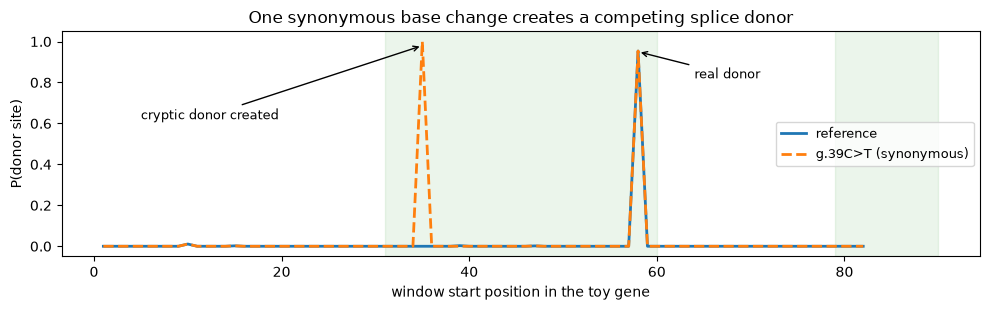

In [5]:
alt_donors = scan_donors(mutate(39, "T"))
x = sorted(REF_DONORS)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(x, [REF_DONORS[i] for i in x], label="reference", linewidth=2)
ax.plot(x, [alt_donors[i] for i in x], label="g.39C>T (synonymous)", linewidth=2, linestyle="--")
ax.axvspan(EXON1[0], EXON1[1], alpha=.08, color="green")
ax.axvspan(EXON2[0], EXON2[1], alpha=.08, color="green")
ax.annotate("real donor", xy=(58, .95), xytext=(64, .82),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate("cryptic donor created", xy=(35, .98), xytext=(5, .62),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel("window start position in the toy gene")
ax.set_ylabel("P(donor site)")
ax.set_title("One synonymous base change creates a competing splice donor")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()
plt.show()

> **This is the slide about synonymous variants, now as a number.** `g.39C>T` does not change a single amino acid, so Step 1 called it `synonymous_variant` and Step 2 has nothing to say about it at all. Yet it creates a donor site as strong as the real one, 23 bases upstream, which would truncate the first exon.
>
> `g.61G>A` is the opposite case and the easy one: it destroys the canonical GT, and the loss score of 0.954 says so.
>
> Compare these with the lecture's thresholds. A delta of 1.000 is far above the 0.8 high-precision cut-off; a delta of 0.003 at the missense control is far below the 0.2 high-sensitivity one. Also note what the delta score is a claim about: **RNA**. It predicts a transcript, not a disease. The next step after a score like this is an RNA assay, not a diagnosis.

---
## Step 4 · A regulatory model, which is the AlphaGenome idea in miniature

**What the real tool does.** AlphaGenome predicts molecular readouts, including expression and chromatin state, directly from sequence, across many cell types. The Atlas serves those predictions precomputed for every possible single-nucleotide variant.

**What we do.** The same shape of computation with one transcription factor and one promoter. Score the TF motif with a PWM, convert to an occupancy, and turn occupancy into a predicted expression level. There is no protein in this calculation anywhere, which is the entire point.

In [6]:
TRAINING_SITES = ["TGACGTCA", "TGACGTCA", "TGACGTCG", "TGACGTAA", "TGACATCA",
                  "TGCCGTCA", "TGACGTCT", "TAACGTCA", "TGACGTCC", "TGACGTGA"]
TF_PWM = build_pwm(TRAINING_SITES)

def tf_occupancy(w):
    if len(w) != 8:
        return 0.0
    logodds = sum(TF_PWM[i][w[i]] for i in range(8))
    return float(1 / (1 + np.exp(-(logodds - 10.5))))

def scan_tf(seq):
    return {i: tf_occupancy(seq[i-1:i+7]) for i in range(1, PROMOTER[1] - 6)}

REF_TF = scan_tf(GENE)
BASAL = 0.15      # transcription that happens without this factor bound

def expression_effect(pos, alt):
    if pos > PROMOTER[1]:
        return {"delta_occupancy": 0.0, "expression_fold": 1.0}
    alt_tf = scan_tf(mutate(pos, alt))
    o_ref, o_alt = max(REF_TF.values()), max(alt_tf.values())
    return {"delta_occupancy": round(o_alt - o_ref, 3),
            "expression_fold": round((BASAL + o_alt) / (BASAL + o_ref), 2)}

print("best TF occupancy in the reference promoter:", round(max(REF_TF.values()), 3))
print()
for pos, alt in [(10, "T"), (16, "G"), (3, "A"), (53, "G")]:
    e = expression_effect(pos, alt)
    print(f"  g.{pos}{GENE[pos-1]}>{alt}  {region_of(pos):9s}  {consequence(pos, alt):22s} "
          f"occupancy {e['delta_occupancy']:+.3f}   expression x{e['expression_fold']}")

best TF occupancy in the reference promoter: 0.831

  g.10G>T  promoter   promoter_variant       occupancy -0.708   expression x0.28
  g.16A>G  promoter   promoter_variant       occupancy -0.375   expression x0.62
  g.3C>A  promoter   promoter_variant       occupancy +0.000   expression x1.0
  g.53A>G  exon1      missense_variant:D8G   occupancy +0.000   expression x1.0


> **g.10G>T knocks expression down to 28% of normal, and nothing in Steps 1 to 3 can see it.** The consequence caller labels it `promoter_variant` and stops. The conservation scorer has no amino acid to score. The splice model finds no GT.
>
> This is the VKORC1 case from the first half of the session. `rs9923231` is a promoter variant that lowers expression, it changes warfarin dosing in practice, and it is invisible to every missense predictor in the course.
>
> Note also `g.16A>G`: expression falls to 62%, a partial effect. Regulatory variants are frequently graded rather than all-or-nothing, which is one reason they are harder to classify under a five-tier system built for protein-coding disease genes.

---
## Step 5 · All three predictors on one panel

Now run everything on nine variants at once and look at the shape of the table rather than at any single number.

In [7]:
PANEL = [(10, "T"), (16, "G"), (36, "G"), (39, "T"), (46, "T"),
         (53, "G"), (61, "A"), (70, "C"), (82, "C")]

def aa_change(cons):
    if not cons.startswith("missense_variant:"):
        return None
    tag = cons.split(":")[1]
    return tag[0], int(tag[1:-1]), tag[-1]

def score_all(pos, alt):
    cons = consequence(pos, alt)
    ac = aa_change(cons)
    sp = spliceai_like(pos, alt)
    return {
        "variant":      f"g.{pos}{GENE[pos-1]}>{alt}",
        "region":       region_of(pos),
        "consequence":  cons,
        "conservation": round(conservation_score(ac[1], ac[0], ac[2]), 2) if ac else np.nan,
        "donor_gain":   sp["donor_gain"],
        "donor_loss":   sp["donor_loss"],
        "expr_fold":    expression_effect(pos, alt)["expression_fold"],
    }

panel = pd.DataFrame([score_all(p, a) for p, a in PANEL])
print(panel.to_string(index=False))

print("\ncells each predictor could not score:")
for col in ["conservation", "donor_gain", "donor_loss", "expr_fold"]:
    blind = panel[col].isna().sum()
    silent = (panel[col] == (1.0 if col == "expr_fold" else 0.0)).sum()
    print(f"  {col:13s}  no score: {blind}   scored but silent: {silent}")

variant   region           consequence  conservation  donor_gain  donor_loss  expr_fold
g.10G>T promoter      promoter_variant           NaN       0.016       0.000       0.28
g.16A>G promoter      promoter_variant           NaN       0.000       0.011       0.62
g.36A>G    exon1    synonymous_variant           NaN       0.000       0.000       1.00
g.39C>T    exon1    synonymous_variant           NaN       1.000       0.003       1.00
g.46A>T    exon1           stop_gained           NaN       0.000       0.002       1.00
g.53A>G    exon1  missense_variant:D8G         -6.66       0.000       0.002       1.00
g.61G>A   intron  splice_donor_variant           NaN       0.000       0.954       1.00
g.70T>C   intron        intron_variant           NaN       0.000       0.000       1.00
g.82T>C    exon2 missense_variant:Y12H         -0.93       0.000       0.000       1.00

cells each predictor could not score:
  conservation   no score: 7   scored but silent: 0
  donor_gain     no score: 0 

> **Read the table by its empty cells, not its full ones.**
>
> - `conservation` is blank for seven of nine variants. It is a missense-only tool, exactly like REVEL and AlphaMissense.
> - `donor_gain` fires once, on a variant the protein-level tools called silent.
> - `expr_fold` fires twice, on variants no other column can see.
> - `g.36A>G` is the control: every predictor is silent and, this time, the variant really is harmless. A row of zeros is not the same as a row of blanks, and conflating the two is the most common error in this kind of analysis.
>
> Three of these nine variants would have been missed by a missense-only pipeline, and nothing in the output would have warned you. That is the coverage matrix from the lecture, produced by your own code.

---
## What you built, and what it leaves out

In roughly 120 lines you have working miniatures of a consequence caller, a conservation scorer, a splice model and a regulatory model. The real tools differ from these in degree, not in kind: deeper training data, learned features instead of hand-built matrices, and genuine calibration. The failure modes you just saw are the real ones.

What this notebook deliberately does **not** have:

- **Real evidence.** No population frequencies, no prior clinical assertions, no functional assay data.
- **Calibration.** Our scores are raw numbers. Turning a number into an evidence strength requires likelihood ratios estimated against curated variant sets, which needs real labels.
- **A ground truth to be wrong against.** Nothing here can be checked, so nothing here can be shown to be miscalibrated or circular.

All three arrive in **Part 2**, where you run the real tools on real variants in real pharmacogenes, with ClinVar assertions as a reference standard, and then examine how trustworthy that reference standard actually is.

*BIOT 6900 · Module 5 Lab, Part 1 · Fall 2026*